Imports and configuration

In [1]:

from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)

# Project paths
PROJECT_ROOT = Path.home() / "Documents" / "CervicalCancerProject"
RESULTS_DIR = PROJECT_ROOT / "results"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"

SPLIT_PATH = RESULTS_DIR / "sipakmed_group_split.csv"

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device selection for Apple Silicon
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Split file exists:", SPLIT_PATH.exists())
print("PyTorch:", torch.__version__)


Device: mps
Split file exists: True
PyTorch: 2.14.1


Load the split and check the labels

In [2]:

# Load the saved dataset split
split_manifest = pd.read_csv(SPLIT_PATH)

CLASS_NAMES = [
    "Dyskeratotic",
    "Koilocytotic",
    "Metaplastic",
    "Parabasal",
    "Superficial-Intermediate",
]

CLASS_TO_IDX = {
    class_name: idx
    for idx, class_name in enumerate(CLASS_NAMES)
}

# Create separate dataframes
train_df = split_manifest[
    split_manifest["split"] == "train"
].reset_index(drop=True)

val_df = split_manifest[
    split_manifest["split"] == "validation"
].reset_index(drop=True)

test_df = split_manifest[
    split_manifest["split"] == "test"
].reset_index(drop=True)

# Encode labels
for df in [train_df, val_df, test_df]:
    df["label"] = df["class_name"].map(CLASS_TO_IDX)

assert split_manifest["image_path"].nunique() == 4049
assert train_df["label"].notna().all()
assert val_df["label"].notna().all()
assert test_df["label"].notna().all()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("\nClass mapping:", CLASS_TO_IDX)
print("\nLoaded split successfully!")


Train: 2718
Validation: 620
Test: 711

Class mapping: {'Dyskeratotic': 0, 'Koilocytotic': 1, 'Metaplastic': 2, 'Parabasal': 3, 'Superficial-Intermediate': 4}

Loaded split successfully!


Define our augmentation configurations

In [3]:

IMAGE_SIZE = 224

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Baseline: mild geometric augmentation
baseline_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Stronger augmentation: still conservative about cell morphology
strong_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.90, 1.10),
    ),
    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.08,
        hue=0.015,
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Validation and test must remain deterministic and unaugmented
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

print("Baseline and stronger augmentation configured.")
print("Evaluation preprocessing has no random augmentation.")


Baseline and stronger augmentation configured.
Evaluation preprocessing has no random augmentation.


Build the dataset and dataloaders

In [4]:

class SIPaKMeDDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = int(row["label"])
        return image, label


BATCH_SIZE = 16
NUM_WORKERS = 0  # Reliable choice for this Mac notebook

train_dataset = SIPaKMeDDataset(
    train_df, transform=strong_train_transform
)
val_dataset = SIPaKMeDDataset(
    val_df, transform=eval_transform
)
test_dataset = SIPaKMeDDataset(
    test_df, transform=eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

images, labels = next(iter(train_loader))

print("Training batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image tensor dtype:", images.dtype)
print("Label examples:", labels[:8].tolist())
print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of test batches:", len(test_loader))


Training batch shape: torch.Size([16, 3, 224, 224])
Labels shape: torch.Size([16])
Image tensor dtype: torch.float32
Label examples: [3, 0, 4, 4, 0, 1, 4, 4]
Number of training batches: 170
Number of validation batches: 39
Number of test batches: 45


In [39]:

strong_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    # Reflection padding before rotation
    transforms.Pad(40, padding_mode="reflect"),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),

    # Random rotation between -35 and +35 degrees
    transforms.RandomRotation(
        degrees=35,
        interpolation=transforms.InterpolationMode.BILINEAR,
        fill=0,
    ),

    transforms.CenterCrop((IMAGE_SIZE, IMAGE_SIZE)),

    # Mild translation and scaling
    transforms.RandomAffine(
        degrees=0,
        translate=(0.03, 0.03),
        scale=(0.95, 1.05),
        interpolation=transforms.InterpolationMode.BILINEAR,
        fill=0,
    ),

    # Controlled color variation
    transforms.ColorJitter(
        brightness=0.08,
        contrast=0.08,
        saturation=0.05,
        hue=0.01,
    ),

    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_dataset = SIPaKMeDDataset(
    train_df,
    transform=strong_train_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

print("Stronger augmentation configured: rotation ±35°")


Stronger augmentation configured: rotation ±35°


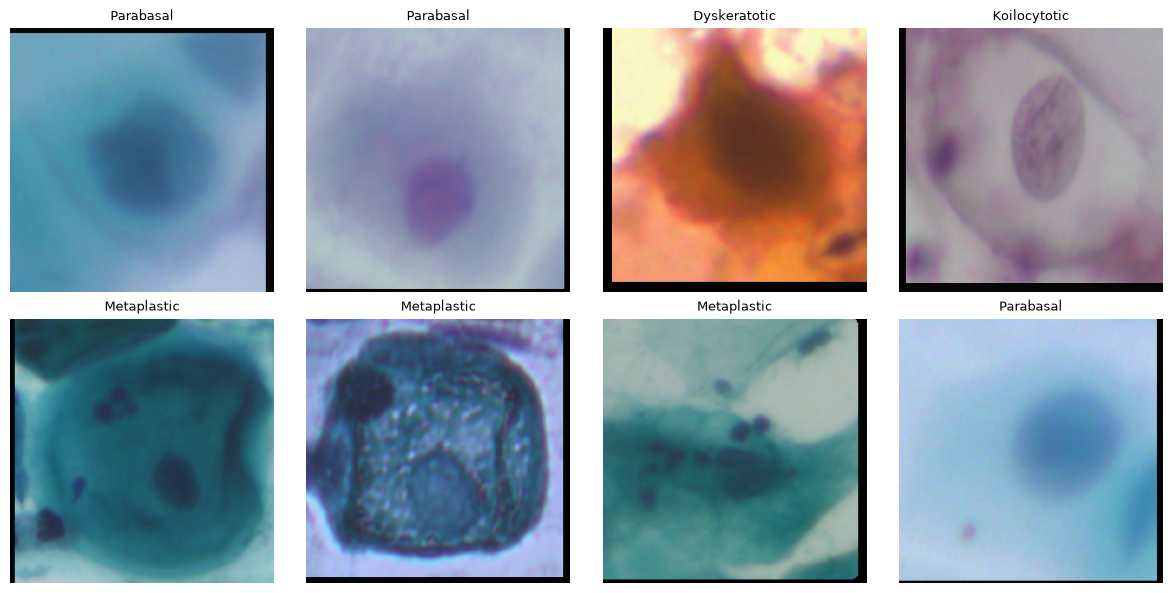

In [40]:

images, labels = next(iter(train_loader))

mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image = (images[i].cpu() * std + mean).clamp(0, 1)
    image = image.permute(1, 2, 0).numpy()

    ax.imshow(image)
    ax.set_title(CLASS_NAMES[int(labels[i])], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


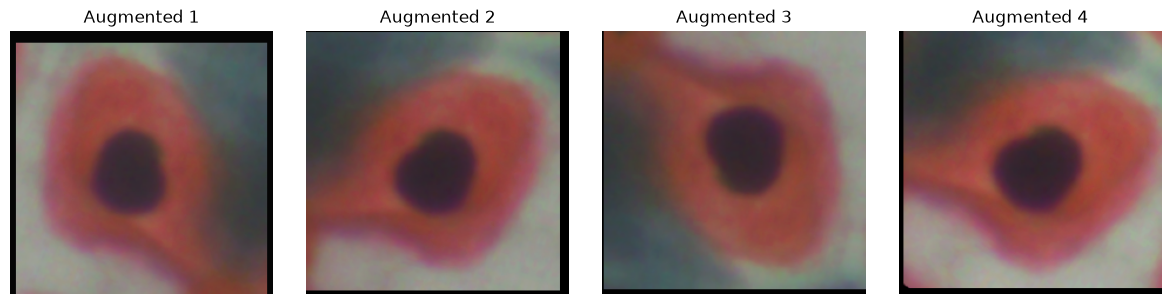

In [41]:

sample_path = train_df.iloc[0]["image_path"]

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

with Image.open(sample_path) as img:
    img = img.convert("RGB")

    for i, ax in enumerate(axes):
        augmented = strong_train_transform(img)

        # Undo ImageNet normalization for display
        mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
        std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
        display_img = (augmented.cpu() * std + mean).clamp(0, 1)

        ax.imshow(display_img.permute(1, 2, 0).numpy())
        ax.set_title(f"Augmented {i + 1}")
        ax.axis("off")

plt.tight_layout()
plt.show()


Create the ResNet18 model

In [42]:

import torch
import torch.nn as nn
from torchvision import models

NUM_CLASSES = len(CLASS_NAMES)

# Load pretrained ResNet18
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Replace the classifier for our five cell classes
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, NUM_CLASSES)

model = model.to(DEVICE)

print("Model: ResNet18")
print("Number of classes:", NUM_CLASSES)
print("Device:", DEVICE)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/harleendhillon/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


Model: ResNet18
Number of classes: 5
Device: mps
Trainable parameters: 11179077


Configure training

In [43]:

import torch.optim as optim

EPOCHS = 12
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
)

print("Loss: CrossEntropyLoss")
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Maximum epochs:", EPOCHS)


Loss: CrossEntropyLoss
Optimizer: AdamW
Learning rate: 0.0003
Maximum epochs: 12


Training and validation functions

In [44]:

import copy
import time
from sklearn.metrics import accuracy_score, f1_score

BEST_CHECKPOINT = CHECKPOINT_DIR / "resnet18_strong_aug_best.pth"
PATIENCE = 4

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    all_labels = []
    all_preds = []
    total_loss = 0.0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.detach().cpu().numpy())
        all_preds.extend(predictions.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(
        all_labels, all_preds, average="macro", zero_division=0
    )

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
    }


print("Training and validation functions defined.")
print("Checkpoint path:", BEST_CHECKPOINT)


Training and validation functions defined.
Checkpoint path: /Users/harleendhillon/Documents/CervicalCancerProject/checkpoints/resnet18_strong_aug_best.pth


Train ResNet18

In [45]:

history = []
best_val_f1 = -1.0
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    train_metrics = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_metrics = run_epoch(
        model, val_loader, criterion
    )

    scheduler.step(val_metrics["macro_f1"])

    improved = val_metrics["macro_f1"] > best_val_f1

    if improved:
        best_val_f1 = val_metrics["macro_f1"]
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_macro_f1": best_val_f1,
            "class_names": CLASS_NAMES,
        }, BEST_CHECKPOINT)
    else:
        epochs_without_improvement += 1

    history.append({
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
    })

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Train acc: {train_metrics['accuracy']:.4f} | "
        f"Val acc: {val_metrics['accuracy']:.4f} | "
        f"Val Macro-F1: {val_metrics['macro_f1']:.4f} | "
        f"{elapsed:.1f}s"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

history_df = pd.DataFrame(history)
history_df.to_csv(
    RESULTS_DIR / "resnet18_strong_aug_history.csv",
    index=False
)

print("\nBest validation Macro-F1:", round(best_val_f1, 4))
print("Checkpoint saved:", BEST_CHECKPOINT)


Epoch 01/12 | Train loss: 0.4752 | Train acc: 0.8466 | Val acc: 0.8355 | Val Macro-F1: 0.8263 | 37.8s
Epoch 02/12 | Train loss: 0.2980 | Train acc: 0.9025 | Val acc: 0.9032 | Val Macro-F1: 0.9044 | 33.5s
Epoch 03/12 | Train loss: 0.2297 | Train acc: 0.9202 | Val acc: 0.8919 | Val Macro-F1: 0.8865 | 32.9s
Epoch 04/12 | Train loss: 0.2192 | Train acc: 0.9286 | Val acc: 0.9403 | Val Macro-F1: 0.9390 | 34.7s
Epoch 05/12 | Train loss: 0.1452 | Train acc: 0.9452 | Val acc: 0.9484 | Val Macro-F1: 0.9472 | 36.5s
Epoch 06/12 | Train loss: 0.1818 | Train acc: 0.9397 | Val acc: 0.9306 | Val Macro-F1: 0.9291 | 33.0s
Epoch 07/12 | Train loss: 0.1509 | Train acc: 0.9492 | Val acc: 0.9097 | Val Macro-F1: 0.9071 | 31.2s
Epoch 08/12 | Train loss: 0.1312 | Train acc: 0.9544 | Val acc: 0.9258 | Val Macro-F1: 0.9232 | 31.0s
Epoch 09/12 | Train loss: 0.1023 | Train acc: 0.9665 | Val acc: 0.9581 | Val Macro-F1: 0.9574 | 35.0s
Epoch 10/12 | Train loss: 0.0669 | Train acc: 0.9779 | Val acc: 0.9677 | Val Macro

In [ ]:
Plot the learning curves

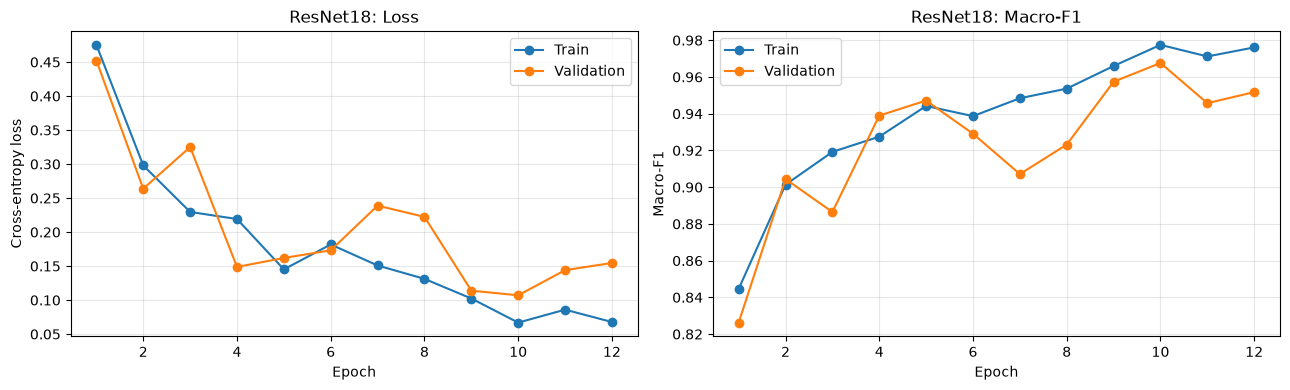

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1
7,8,0.131227,0.954378,0.953646,0.222372,0.925806,0.923184
8,9,0.102339,0.966519,0.965984,0.113855,0.958065,0.957415
9,10,0.066908,0.977925,0.977477,0.107053,0.967742,0.967618
10,11,0.085943,0.971670,0.971175,0.144054,0.946774,0.945734
11,12,0.067808,0.976453,0.976100,0.154597,0.953226,0.951765


In [48]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
axes[0].set_title("ResNet18: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_df["epoch"], history_df["train_macro_f1"], marker="o", label="Train")
axes[1].plot(history_df["epoch"], history_df["val_macro_f1"], marker="o", label="Validation")
axes[1].set_title("ResNet18: Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "resnet18_learning_curves.png", dpi=200)
plt.show()

display(history_df.tail())


In [49]:

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
model.eval()

print("Best checkpoint loaded.")
print("Best epoch:", checkpoint["epoch"])
print("Best validation Macro-F1:", round(checkpoint["best_val_macro_f1"], 4))


Best checkpoint loaded.
Best epoch: 10
Best validation Macro-F1: 0.9676


Evaluate on the held-out test set

Test accuracy:          0.9550
Test Macro-F1:          0.9562
Test balanced accuracy: 0.9597

Per-class report:


,precision,recall,f1-score,support
Dyskeratotic,0.886525,1.000000,0.939850,125.000000
Koilocytotic,0.969512,0.873626,0.919075,182.000000
Metaplastic,0.920863,0.962406,0.941176,133.000000
Parabasal,1.000000,0.962617,0.980952,107.000000
Superficial-Intermediate,1.000000,1.000000,1.000000,164.000000
accuracy,0.954993,0.954993,0.954993,0.954993
macro avg,0.955380,0.959730,0.956211,711.000000
weighted avg,0.957443,0.954993,0.954840,711.000000


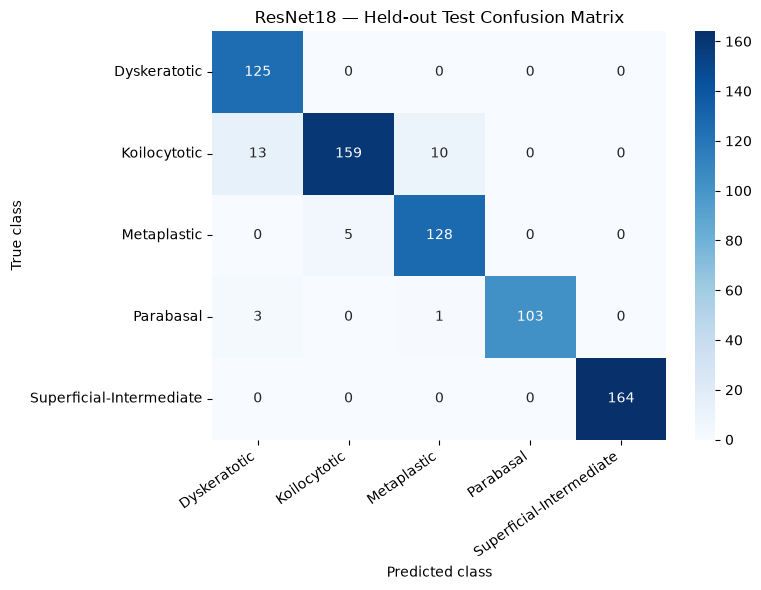

Saved test predictions and confusion matrix.


In [50]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)
import seaborn as sns

all_labels = []
all_preds = []

model.eval()
with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_preds.extend(predictions.cpu().numpy())

test_accuracy = accuracy_score(all_labels, all_preds)
test_macro_f1 = f1_score(
    all_labels, all_preds, average="macro", zero_division=0
)
test_balanced_accuracy = balanced_accuracy_score(all_labels, all_preds)

print(f"Test accuracy:          {test_accuracy:.4f}")
print(f"Test Macro-F1:          {test_macro_f1:.4f}")
print(f"Test balanced accuracy: {test_balanced_accuracy:.4f}")

print("\nPer-class report:")
report = classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
    output_dict=True,
)
display(pd.DataFrame(report).T)

cm = confusion_matrix(
    all_labels, all_preds, labels=list(range(len(CLASS_NAMES)))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("ResNet18 — Held-out Test Confusion Matrix")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "resnet18_test_confusion_matrix.png", dpi=200)
plt.show()

# Save actual test predictions for reproducible reporting
predictions_df = test_df[["image_path", "class_name", "label"]].copy()
predictions_df["predicted_label"] = all_preds
predictions_df["predicted_class"] = [
    CLASS_NAMES[p] for p in all_preds
]
predictions_df.to_csv(
    RESULTS_DIR / "resnet18_test_predictions.csv",
    index=False,
)

print("Saved test predictions and confusion matrix.")


Save the baseline result

In [51]:

baseline_result = {
    "model": "ResNet18",
    "augmentation": "strong",
    "optimizer": "AdamW",
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_macro_f1,
    "test_balanced_accuracy": test_balanced_accuracy,
    "best_validation_macro_f1": checkpoint["best_val_macro_f1"],
    "test_images": len(test_df),
}

baseline_path = RESULTS_DIR / "experiment_results.csv"
new_result = pd.DataFrame([baseline_result])

if baseline_path.exists():
    existing = pd.read_csv(baseline_path)
    existing = existing[
        ~(
            (existing["model"] == "ResNet18")
            & (existing["augmentation"] == "strong")
            & (existing["optimizer"] == "AdamW")
        )
    ]
    new_result = pd.concat([existing, new_result], ignore_index=True)

new_result.to_csv(baseline_path, index=False)

print(new_result.tail())
print("\nSaved baseline metrics to:", baseline_path)


      model augmentation optimizer  test_accuracy  test_macro_f1  \
0  ResNet18       strong     AdamW       0.954993       0.956211   

   test_balanced_accuracy  best_validation_macro_f1  test_images  
0                 0.95973                  0.967618          711  

Saved baseline metrics to: /Users/harleendhillon/Documents/CervicalCancerProject/results/experiment_results.csv


Set up the mild-augmentation experiment

In [52]:

# Mild augmentation experiment
baseline_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=10,
        interpolation=transforms.InterpolationMode.BILINEAR,
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

baseline_train_dataset = SIPaKMeDDataset(
    train_df,
    transform=baseline_train_transform,
)

baseline_train_loader = DataLoader(
    baseline_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

print("Mild augmentation configured.")
print("Training images:", len(baseline_train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))


Mild augmentation configured.
Training images: 2718
Validation images: 620
Test images: 711


Initialize a fresh ResNet18

In [53]:

import torch.optim as optim

baseline_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)
baseline_model.fc = nn.Linear(
    baseline_model.fc.in_features,
    NUM_CLASSES,
)
baseline_model = baseline_model.to(DEVICE)

baseline_optimizer = optim.AdamW(
    baseline_model.parameters(),
    lr=3e-4,
    weight_decay=1e-4,
)

baseline_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    baseline_optimizer,
    mode="max",
    factor=0.5,
    patience=2,
)

baseline_checkpoint_path = (
    CHECKPOINT_DIR / "resnet18_mild_aug_best.pth"
)

print("Fresh ResNet18 initialized.")
print("Checkpoint:", baseline_checkpoint_path)


Fresh ResNet18 initialized.
Checkpoint: /Users/harleendhillon/Documents/CervicalCancerProject/checkpoints/resnet18_mild_aug_best.pth


In [54]:

baseline_history = []
baseline_best_f1 = -1.0
baseline_wait = 0
PATIENCE = 4

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    train_metrics = run_epoch(
        baseline_model,
        baseline_train_loader,
        criterion,
        baseline_optimizer,
    )

    val_metrics = run_epoch(
        baseline_model,
        val_loader,
        criterion,
    )

    baseline_scheduler.step(val_metrics["macro_f1"])

    if val_metrics["macro_f1"] > baseline_best_f1:
        baseline_best_f1 = val_metrics["macro_f1"]
        baseline_wait = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": baseline_model.state_dict(),
            "best_val_macro_f1": baseline_best_f1,
            "class_names": CLASS_NAMES,
        }, baseline_checkpoint_path)
    else:
        baseline_wait += 1

    baseline_history.append({
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train acc: {train_metrics['accuracy']:.4f} | "
        f"Val acc: {val_metrics['accuracy']:.4f} | "
        f"Val Macro-F1: {val_metrics['macro_f1']:.4f} | "
        f"{time.time() - start_time:.1f}s"
    )

    if baseline_wait >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

baseline_history_df = pd.DataFrame(baseline_history)
baseline_history_df.to_csv(
    RESULTS_DIR / "resnet18_mild_aug_history.csv",
    index=False,
)

print("\nBest validation Macro-F1:", round(baseline_best_f1, 4))
print("Checkpoint saved:", baseline_checkpoint_path)


Epoch 01/12 | Train acc: 0.8561 | Val acc: 0.8935 | Val Macro-F1: 0.8897 | 25.5s
Epoch 02/12 | Train acc: 0.9124 | Val acc: 0.8774 | Val Macro-F1: 0.8720 | 24.7s
Epoch 03/12 | Train acc: 0.9352 | Val acc: 0.9145 | Val Macro-F1: 0.9110 | 24.6s
Epoch 04/12 | Train acc: 0.9474 | Val acc: 0.9032 | Val Macro-F1: 0.8977 | 24.9s
Epoch 05/12 | Train acc: 0.9533 | Val acc: 0.9113 | Val Macro-F1: 0.9092 | 27.0s
Epoch 06/12 | Train acc: 0.9724 | Val acc: 0.9226 | Val Macro-F1: 0.9211 | 27.2s
Epoch 07/12 | Train acc: 0.9684 | Val acc: 0.9290 | Val Macro-F1: 0.9288 | 25.4s
Epoch 08/12 | Train acc: 0.9573 | Val acc: 0.9274 | Val Macro-F1: 0.9237 | 25.2s
Epoch 09/12 | Train acc: 0.9768 | Val acc: 0.9452 | Val Macro-F1: 0.9429 | 25.2s
Epoch 10/12 | Train acc: 0.9650 | Val acc: 0.9097 | Val Macro-F1: 0.9089 | 25.2s
Epoch 11/12 | Train acc: 0.9746 | Val acc: 0.9387 | Val Macro-F1: 0.9371 | 25.2s
Epoch 12/12 | Train acc: 0.9820 | Val acc: 0.9403 | Val Macro-F1: 0.9387 | 26.0s

Best validation Macro-F1: 0

Compare the two experiments

,experiment,best_val_accuracy,best_val_macro_f1,best_epoch
0,Strong augmentation,0.9677,0.9676,10
1,Mild augmentation,0.9452,0.9429,9


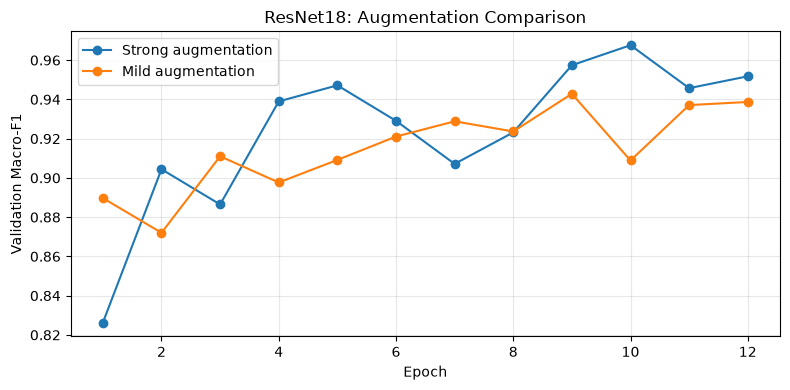

In [55]:

# Load the history from the strong-augmentation experiment
strong_history_df = pd.read_csv(
    RESULTS_DIR / "resnet18_strong_aug_history.csv"
)

comparison = pd.DataFrame([
    {
        "experiment": "Strong augmentation",
        "best_val_accuracy": strong_history_df.loc[
            strong_history_df["val_macro_f1"].idxmax(),
            "val_accuracy"
        ],
        "best_val_macro_f1": strong_history_df["val_macro_f1"].max(),
        "best_epoch": int(
            strong_history_df.loc[
                strong_history_df["val_macro_f1"].idxmax(),
                "epoch"
            ]
        ),
    },
    {
        "experiment": "Mild augmentation",
        "best_val_accuracy": baseline_history_df.loc[
            baseline_history_df["val_macro_f1"].idxmax(),
            "val_accuracy"
        ],
        "best_val_macro_f1": baseline_history_df["val_macro_f1"].max(),
        "best_epoch": int(
            baseline_history_df.loc[
                baseline_history_df["val_macro_f1"].idxmax(),
                "epoch"
            ]
        ),
    },
])

display(comparison.round(4))

plt.figure(figsize=(8, 4))
plt.plot(
    strong_history_df["epoch"],
    strong_history_df["val_macro_f1"],
    marker="o",
    label="Strong augmentation",
)
plt.plot(
    baseline_history_df["epoch"],
    baseline_history_df["val_macro_f1"],
    marker="o",
    label="Mild augmentation",
)
plt.xlabel("Epoch")
plt.ylabel("Validation Macro-F1")
plt.title("ResNet18: Augmentation Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "augmentation_comparison.png", dpi=200)
plt.show()
